# 모두마켓 웹 트래픽 — 로그 분석 리포트

## 1. 데이터 개요
- 로그 줄 수: 1,500줄
- 기간: 2025-03-01 ~ 2025-03-07
- 추출 필드: ip, ts, method, path, status, size
- 결측값 0개, 중복 행 0개

## 2. 파싱
- 정규식 추출 실패: 0건
- 날짜 파싱(%d/%b/%Y:%H:%M:%S) 실패: 0건

## 3. 트래픽 요약
- 총 요청 수: 1,500건 (고유 IP 118개)
- 요청 방식: GET 1157건, POST 343건
- 상태 코드: 200 964건, 301 188건, 404 178건, 500 170건
- 오류 응답(4xx·5xx) 비율: 23.2%
- 요청 많은 경로 TOP 3: / 184건, /search 175건, /cart 173건

## 4. 시간 패턴
- 하루 중 가장 몰린 시각: 22시 (82건)
- 하루 중 가장 한산한 시각: 20시 (46건)
- 가장 몰린 1시간(resample 'h'): 2025-03-07 22:00:00 (21건)
- 요일 최다: Thursday 225건 / 최소: Wednesday 198건

## 5. 다음 분석 제안 근거
- 경로별 오류율 TOP 3: /checkout 28.0%, /products/456 25.1%, /cart 24.9%
- 요청 많은 IP TOP 3: 198.51.100.41 24건, 203.0.113.58 21건, 198.51.100.52 19건
- IP당 평균 요청 수: 12.7건


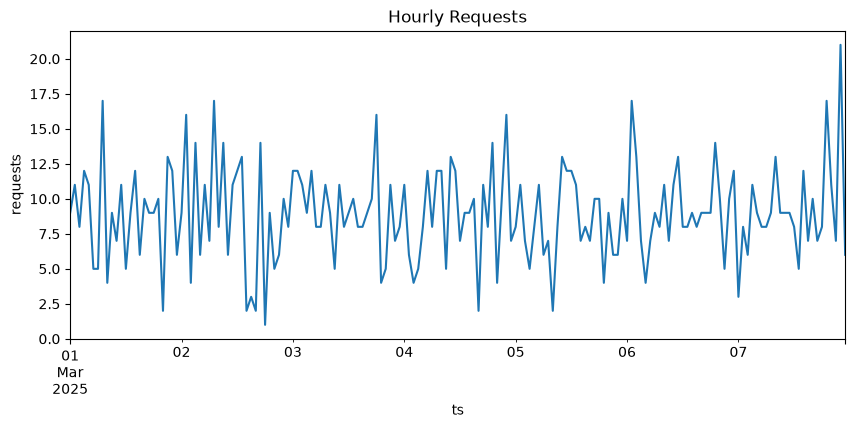

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ── 1. 웹 로그 생성 ──
np.random.seed(7)
n_logs = 1500
ips = [f"203.0.113.{k}" for k in range(1, 60)] + [f"198.51.100.{k}" for k in range(1, 60)]
paths = ["/", "/products", "/products/123", "/products/456", "/cart",
         "/checkout", "/login", "/search", "/api/orders"]
methods = ["GET", "GET", "GET", "POST"]
statuses = [200, 200, 200, 200, 200, 404, 500, 301]
log_times = pd.to_datetime("2025-03-01") + pd.to_timedelta(
    np.sort(np.random.randint(0, 7 * 24 * 3600, n_logs)), unit="s")
lines = []
for i in range(n_logs):
    ip = np.random.choice(ips)
    ts_str = log_times[i].strftime("%d/%b/%Y:%H:%M:%S")
    m = np.random.choice(methods)
    p = np.random.choice(paths)
    st = np.random.choice(statuses)
    sz = np.random.randint(200, 5000)
    lines.append(f'{ip} - - [{ts_str}] "{m} {p} HTTP/1.1" {st} {sz}')
web_logs = pd.DataFrame({"raw": lines})

# ── 2. 정규식 파싱 + 타입 변환 ──
pattern = (r'(?P<ip>\d+\.\d+\.\d+\.\d+) - - \[(?P<ts>[^\]]+)\] '
           r'"(?P<method>\w+) (?P<path>\S+) [^"]*" (?P<status>\d+) (?P<size>\d+)')
logs = web_logs["raw"].str.extract(pattern)
extract_fail = logs.isna().any(axis=1).sum()
logs["ts"] = pd.to_datetime(logs["ts"], format="%d/%b/%Y:%H:%M:%S", errors="coerce")
logs["status"] = logs["status"].astype(int)
logs["size"] = logs["size"].astype(int)

# ── 3. 집계 ──
error_rate = (logs["status"] >= 400).mean() * 100
top3 = logs["path"].value_counts().head(3)
hourly = logs.set_index("ts").resample("h").size()
by_hour = logs["ts"].dt.hour.value_counts().sort_index()
by_day = logs["ts"].dt.day_name().value_counts()
path_err = (logs.assign(is_error=logs["status"] >= 400)
                .groupby("path")["is_error"].mean()
                .sort_values(ascending=False) * 100)
ip_counts = logs["ip"].value_counts()

# ── 4. 리포트 출력 ──
print("# 모두마켓 웹 트래픽 — 로그 분석 리포트\n")
print("## 1. 데이터 개요")
print(f"- 로그 줄 수: {len(web_logs):,}줄")
print(f"- 기간: {logs['ts'].min().date()} ~ {logs['ts'].max().date()}")
print(f"- 추출 필드: {', '.join(logs.columns)}")
print(f"- 결측값 {web_logs.isna().sum().sum()}개, 중복 행 {web_logs.duplicated().sum()}개\n")

print("## 2. 파싱")
print(f"- 정규식 추출 실패: {extract_fail}건")
print(f"- 날짜 파싱(%d/%b/%Y:%H:%M:%S) 실패: {logs['ts'].isna().sum()}건\n")

print("## 3. 트래픽 요약")
print(f"- 총 요청 수: {len(logs):,}건 (고유 IP {logs['ip'].nunique()}개)")
print("- 요청 방식: " + ", ".join(f"{k} {v}건" for k, v in logs["method"].value_counts().items()))
print("- 상태 코드: " + ", ".join(f"{k} {v}건" for k, v in logs["status"].value_counts().items()))
print(f"- 오류 응답(4xx·5xx) 비율: {error_rate:.1f}%")
print("- 요청 많은 경로 TOP 3: " + ", ".join(f"{p} {c}건" for p, c in top3.items()) + "\n")

print("## 4. 시간 패턴")
print(f"- 하루 중 가장 몰린 시각: {by_hour.idxmax()}시 ({by_hour.max()}건)")
print(f"- 하루 중 가장 한산한 시각: {by_hour.idxmin()}시 ({by_hour.min()}건)")
print(f"- 가장 몰린 1시간(resample 'h'): {hourly.idxmax()} ({hourly.max()}건)")
print(f"- 요일 최다: {by_day.idxmax()} {by_day.max()}건 / 최소: {by_day.idxmin()} {by_day.min()}건\n")

print("## 5. 다음 분석 제안 근거")
print("- 경로별 오류율 TOP 3: " + ", ".join(f"{p} {r:.1f}%" for p, r in path_err.head(3).items()))
print("- 요청 많은 IP TOP 3: " + ", ".join(f"{ip} {c}건" for ip, c in ip_counts.head(3).items()))
print(f"- IP당 평균 요청 수: {ip_counts.mean():.1f}건")

# ── 5. 그래프 ──
hourly.plot(title="Hourly Requests", figsize=(10, 4))
plt.ylabel("requests")
plt.show()